First 5 rows:
   age  sex   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  \
0   63  1.0  233.0  1.0        0    150.0      0      2.3    0.0  0.0     1   
1   37  1.0  250.0  0.0        1    187.0      0      3.5    0.0  0.0     2   
2   41  0.0  204.0  0.0        0    172.0      0      1.4    2.0  0.0     2   
3   56  1.0  236.0  0.0        1    178.0      0      0.8    2.0  0.0     2   
4   57  0.0  354.0  0.0        1    163.0      1      0.6    2.0  0.0     2   

   target  
0     1.0  
1     1.0  
2     1.0  
3     1.0  
4     1.0  

Dataset Shape:
(303, 12)

Missing Values:
age          0
sex          1
chol         1
fbs          2
restecg      0
thalach      1
exang        0
oldpeak      1
slope      209
ca           1
thal         0
target       1
dtype: int64

Decision Tree Accuracy: 100.0 %

Confusion Matrix:
[[18]]

Classification Report:
              precision    recall  f1-score   support

         1.0       1.00      1.00      1.00        18

    accura

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:620: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


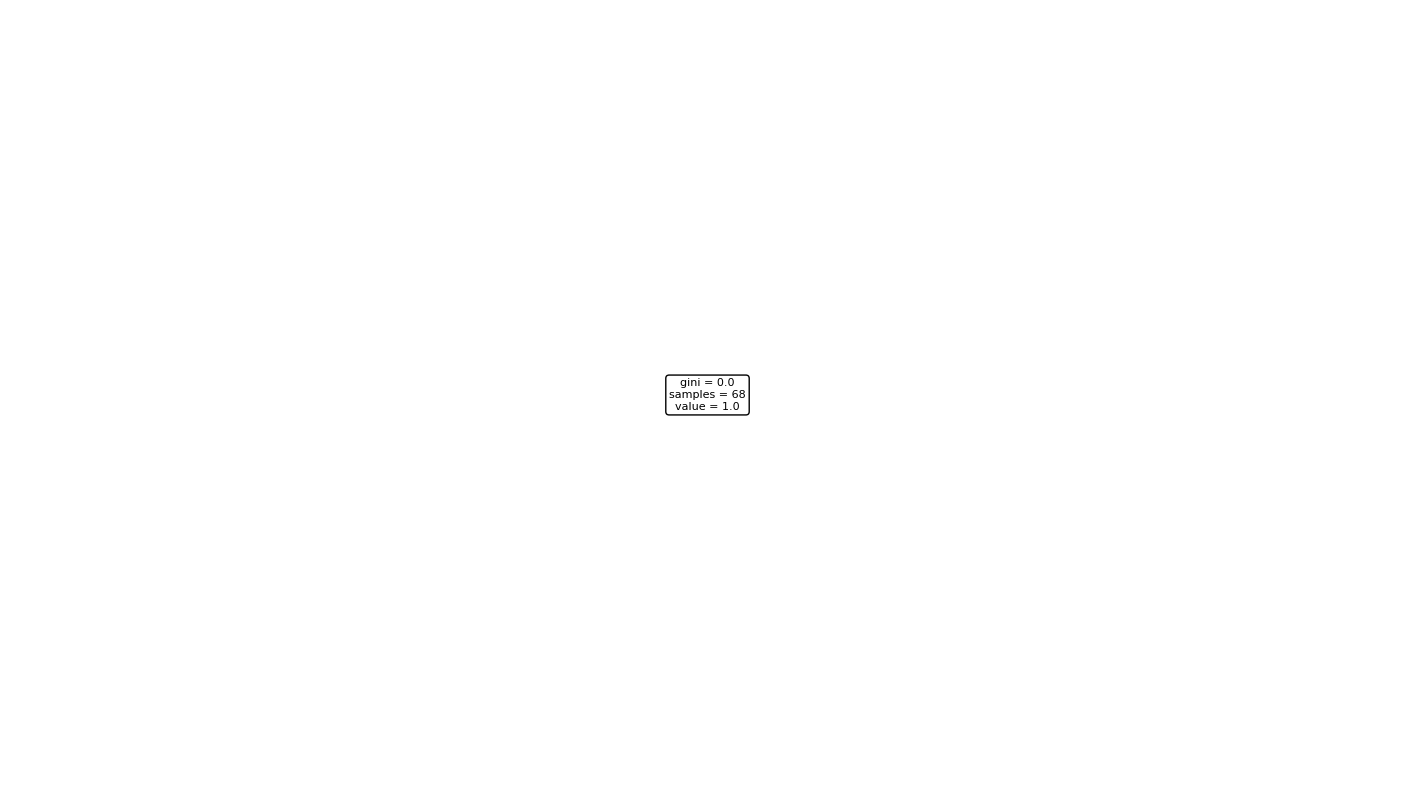

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Load the dataset
df = pd.read_csv("heart.csv")

# Display dataset information
print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

# Remove rows containing missing values
df.dropna(inplace=True)

# Separate input features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Predict test data
y_pred = dt_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nDecision Tree Accuracy:", accuracy * 100, "%")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display feature importance
print("\nFeature Importance:")
for name, importance in zip(X.columns, dt_model.feature_importances_):
    print(name, ":", importance)

# Visualize the decision tree
plt.figure(figsize=(18, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()
